# 01 — FLCHAIN Data Preprocessing & EDA

## 01 — Install Packages

In [1]:
import importlib.util, subprocess, sys
packages = {"sksurv": "scikit-survival", "lifelines": "lifelines", "seaborn": "seaborn", "joblib": "joblib"}
missing = [pip_name for module, pip_name in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("Packages ready. If imports fail after installation, restart session once.")

Packages ready. If imports fail after installation, restart session once.


## 02 — Import Libraries

In [2]:
from pathlib import Path
import json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sksurv.datasets import load_flchain
SEED=42
OUT = Path('/content/outputs_flchain') if Path('/content').exists() else Path('outputs_flchain')
OUT.mkdir(parents=True, exist_ok=True)

## 03 — Load FLCHAIN Dataset

In [3]:
X, y = load_flchain()
print('Features:',X.shape,'Target names:',y.dtype.names)
display(X.head())
assert len(X)==7874 and len(y)==len(X)

Features: (7874, 9) Target names: ('death', 'futime')


,age,chapter,creatinine,flc.grp,kappa,lambda,mgus,sample.yr,sex
0,97.0,Circulatory,1.7,10,5.70,4.860,no,1997,F
1,92.0,Neoplasms,0.9,1,0.87,0.683,no,2000,F
2,94.0,Circulatory,1.4,10,4.36,3.850,no,1997,F
3,92.0,Circulatory,1.0,9,2.42,2.220,no,1996,F
4,93.0,Circulatory,1.1,6,1.32,1.690,no,1996,F


## 04 — Define Survival Endpoint

In [4]:
target_names = y.dtype.names
assert len(target_names)==2
print('Target:',target_names)
assert 'death' in target_names and 'futime' in target_names
full = X.copy()
full['event'] = y['death'].astype(bool).astype(int)
full['time'] = y['futime'].astype(float)
full['row_id'] = np.arange(len(full))
assert full['time'].notna().all() and (full['time'] >= 0).all()
assert full['event'].isin([0,1]).all()
print(full[['event','time']].describe())

Target: ('death', 'futime')
             event         time
count  7874.000000  7874.000000
mean      0.275464  3661.042291
std       0.446776  1432.677330
min       0.000000     0.000000
25%       0.000000  2852.000000
50%       0.000000  4302.000000
75%       1.000000  4773.000000
max       1.000000  5215.000000


In [5]:
# Verify duration values AFTER constructing the survival endpoint.
print("Missing follow-up:", int(full['time'].isna().sum()))
print("Zero follow-up:", int((full['time'] == 0).sum()))
print("Negative follow-up:", int((full['time'] < 0).sum()))
print("Minimum follow-up (days):", full['time'].min())


Missing follow-up: 0
Zero follow-up: 3
Negative follow-up: 0
Minimum follow-up (days): 0.0


## 05 — Remove Outcome Leakage

In [6]:
LEAKAGE = ['chapter']
assert all(c in full.columns for c in LEAKAGE)
feature_columns = [c for c in X.columns if c not in LEAKAGE]
assert not {'chapter','time','event','row_id'}.intersection(feature_columns)
print('Excluded:',LEAKAGE)
print('Predictors:',feature_columns)

Excluded: ['chapter']
Predictors: ['age', 'creatinine', 'flc.grp', 'kappa', 'lambda', 'mgus', 'sample.yr', 'sex']


## 06 — Dataset Overview

In [7]:
print('Patients:',len(full))
print('Events:',int(full.event.sum()))
print('Censored:',int((full.event==0).sum()))
display(full[feature_columns].dtypes.to_frame('dtype'))

Patients: 7874
Events: 2169
Censored: 5705


,dtype
age,float64
creatinine,float64
flc.grp,category
kappa,float64
lambda,float64
mgus,category
sample.yr,category
sex,category


## 07 — Missing Values

In [8]:
missing = full[feature_columns+['time','event']].isna().sum().sort_values(ascending=False)
display(missing.to_frame('missing'))
missing.to_csv(OUT/'missing_values.csv',header=['missing'])

,missing
creatinine,1350
age,0
flc.grp,0
kappa,0
lambda,0
mgus,0
sample.yr,0
sex,0
time,0
event,0


## 08 — Duplicate and Range Checks

In [9]:

print("Duplicated predictor rows:", full[feature_columns].duplicated().sum())
print("Repeated row IDs:", full.row_id.duplicated().sum())

print("Missing follow-up:", full["time"].isna().sum())
print("Zero follow-up:", (full["time"] == 0).sum())
print("Negative follow-up:", (full["time"] < 0).sum())
print("Invalid events:", (~full["event"].isin([0, 1])).sum())

for col in ["age", "kappa", "lambda", "creatinine"]:
    if col in full.columns:
        s = pd.to_numeric(full[col], errors="coerce")
        print(col, "negative values:", int((s < 0).sum()))

assert full["time"].notna().all()
assert (full["time"] >= 0).all()
assert full["event"].isin([0, 1]).all()


Duplicated predictor rows: 1
Repeated row IDs: 0
Missing follow-up: 0
Zero follow-up: 3
Negative follow-up: 0
Invalid events: 0
age negative values: 0
kappa negative values: 0
lambda negative values: 0
creatinine negative values: 0


## 09 — Summary Statistics

In [10]:
display(full[feature_columns].describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,7874.0,NaN,NaN,NaN,64.293117,10.462719,50.0,55.0,63.0,72.0,101.0
creatinine,6524.0,NaN,NaN,NaN,1.093516,0.416507,0.4,0.9,1.0,1.2,10.8
flc.grp,7874,10,3,820,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kappa,7874.0,NaN,NaN,NaN,1.430881,0.896774,0.01,0.96,1.27,1.68,20.5
lambda,7874.0,NaN,NaN,NaN,1.702624,1.030732,0.04,1.2,1.51,1.92,26.6
mgus,7874,2,no,7759,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sample.yr,7874,9,1996,3491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,7874,2,F,4350,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 10 — Event and Censoring Distribution

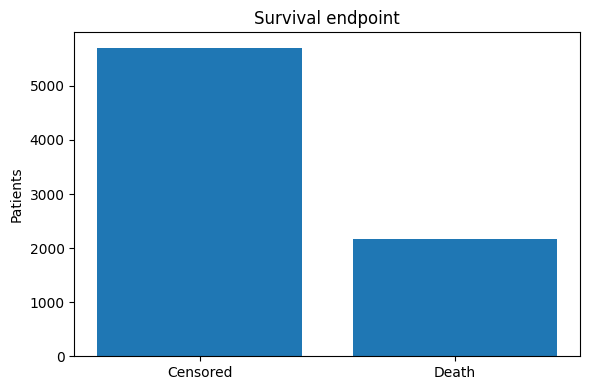

In [11]:
counts=full.event.value_counts().reindex([0,1],fill_value=0)
fig,ax=plt.subplots(figsize=(6,4))
ax.bar(['Censored','Death'],counts.values)
ax.set_ylabel('Patients');ax.set_title('Survival endpoint')
plt.tight_layout();plt.savefig(OUT/'event_distribution.png',dpi=150);plt.show()

## 11 — Follow-up Distribution

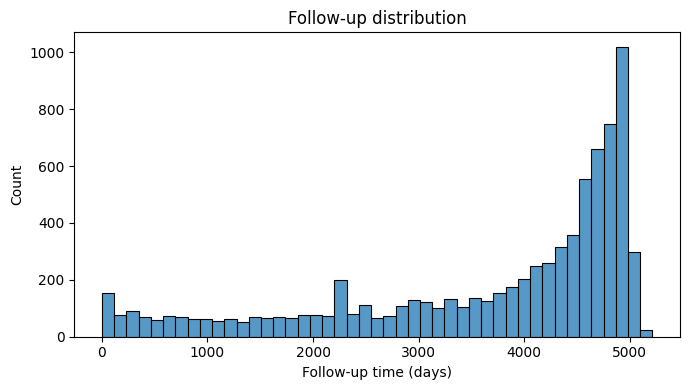

In [12]:
fig,ax=plt.subplots(figsize=(7,4))
sns.histplot(full['time'],bins=45,ax=ax)
ax.set(xlabel='Follow-up time (days)',title='Follow-up distribution')
plt.tight_layout();plt.savefig(OUT/'followup_distribution.png',dpi=150);plt.show()

## 12 — Numerical Feature Distributions

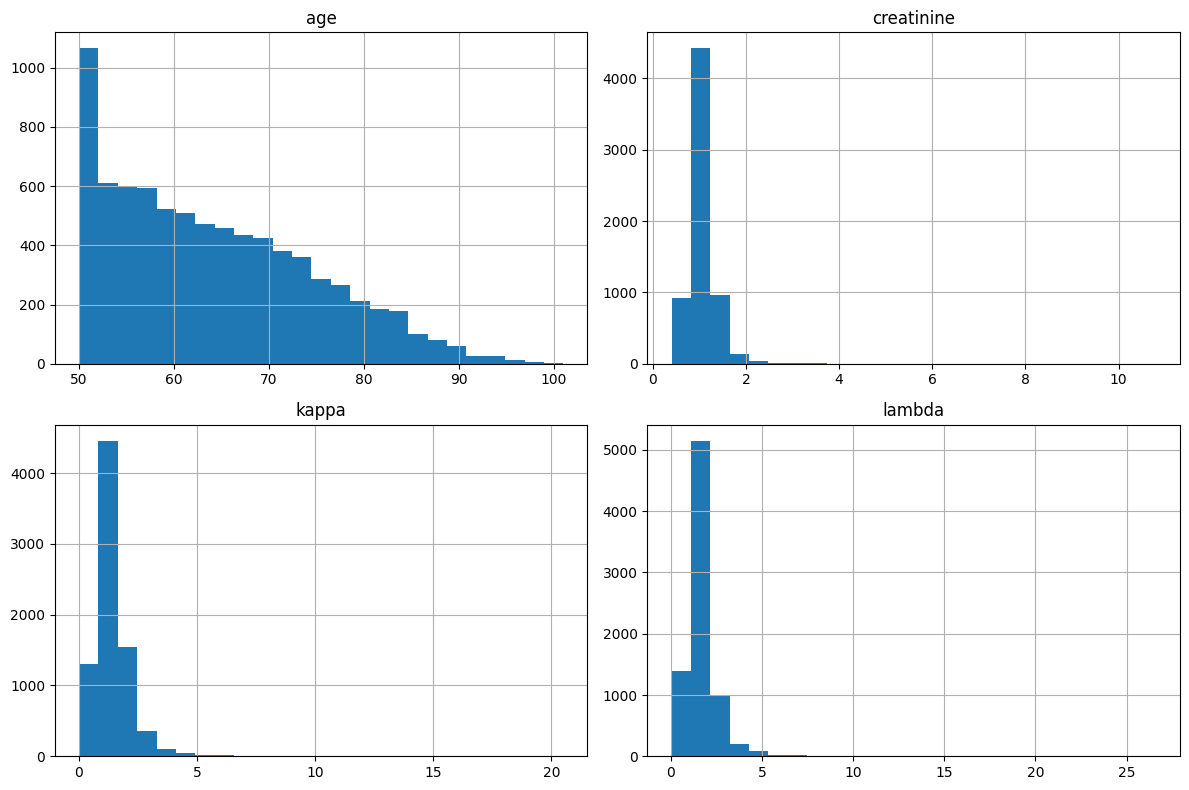

In [13]:
numeric=full[feature_columns].select_dtypes(include=np.number).columns.tolist()
full[numeric].hist(figsize=(12,8),bins=25)
plt.tight_layout();plt.savefig(OUT/'numeric_distributions.png',dpi=150);plt.show()

## 13 — Categorical Feature Distributions

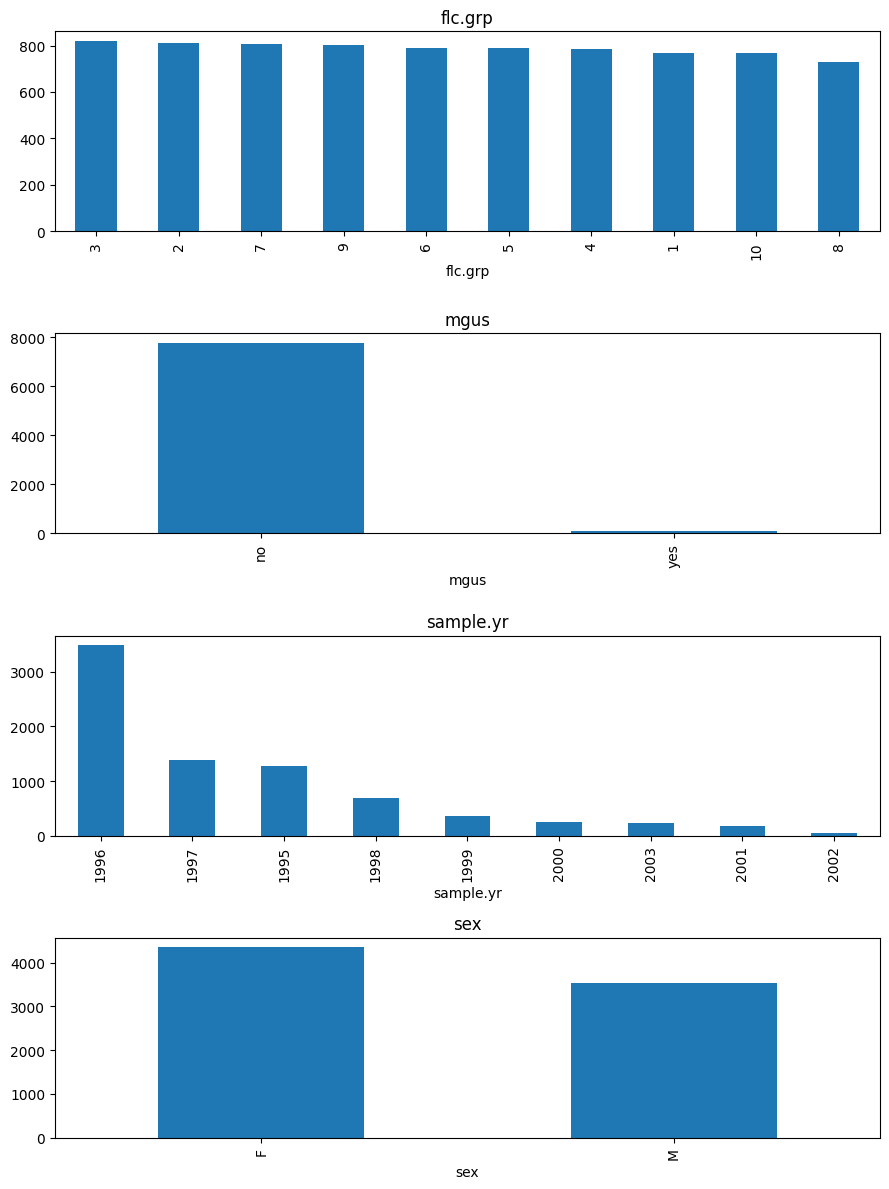

In [14]:
categorical=[c for c in feature_columns if c not in numeric]
fig,axes=plt.subplots(max(1,len(categorical)),1,figsize=(9,3*max(1,len(categorical))))
axes=np.atleast_1d(axes)
for ax,col in zip(axes,categorical):
    full[col].astype(str).value_counts().head(15).plot(kind='bar',ax=ax,title=col)
plt.tight_layout();plt.savefig(OUT/'categorical_distributions.png',dpi=150);plt.show()

## 14 — Train Test Split

In [15]:
idx_train,idx_test=train_test_split(np.arange(len(full)),test_size=0.2,random_state=SEED,stratify=full.event)
train=full.iloc[idx_train][['row_id',*feature_columns,'time','event']].copy()
test=full.iloc[idx_test][['row_id',*feature_columns,'time','event']].copy()
assert len(train)+len(test)==len(full)
assert set(train.row_id).isdisjoint(set(test.row_id))
print('Train',train.shape,'Test',test.shape)

Train (6299, 11) Test (1575, 11)


## 15 — Train Test Endpoint Balance

In [16]:
display(pd.DataFrame({'n':[len(train),len(test)],'events':[int(train.event.sum()),int(test.event.sum())], 'event_rate':[train.event.mean(),test.event.mean()]},index=['Train','Test']))

,n,events,event_rate
Train,6299,1735,0.275441
Test,1575,434,0.275556


## 16 — Preprocessing Plan

In [17]:
numerical = train[feature_columns].select_dtypes(include=np.number).columns.tolist()
categorical = [c for c in feature_columns if c not in numerical]
print('Numeric (median imputation + scaling where needed):',numerical)
print('Categorical (most frequent imputation + one hot):',categorical)
print('Fit preprocessing on training only; transform validation/test without refitting.')

Numeric (median imputation + scaling where needed): ['age', 'creatinine', 'kappa', 'lambda']
Categorical (most frequent imputation + one hot): ['flc.grp', 'mgus', 'sample.yr', 'sex']
Fit preprocessing on training only; transform validation/test without refitting.


In [18]:

# Missing values by split
print("Training missing values:")
print(train[feature_columns].isna().sum())

print("\nTesting missing values:")
print(test[feature_columns].isna().sum())

# Zero follow-up records
zero_cases = full.loc[
    full["time"] == 0,
    ["row_id", "time", "event"]
]

print("\nZero follow-up records:")
display(zero_cases)

# Check for missing survival targets
assert train[["time", "event"]].notna().all().all()
assert test[["time", "event"]].notna().all().all()

print("\nPreprocessing will be fitted on training data only.")
print("Zero follow-up cases are retained: these are observed events at day 0 in the source data.")
print("They are NOT relabeled, deleted, or assigned artificial durations.")
print("We report this as a data limitation and keep the same event/time definitions in all notebooks.")


Training missing values:
age              0
creatinine    1078
flc.grp          0
kappa            0
lambda           0
mgus             0
sample.yr        0
sex              0
dtype: int64

Testing missing values:
age             0
creatinine    272
flc.grp         0
kappa           0
lambda          0
mgus            0
sample.yr       0
sex             0
dtype: int64

Zero follow-up records:


,row_id,time,event
30,30,0.0,1
53,53,0.0,1
721,721,0.0,1



Preprocessing will be fitted on training data only.
Zero follow-up cases are retained: these are observed events at day 0 in the source data.
They are NOT relabeled, deleted, or assigned artificial durations.
We report this as a data limitation and keep the same event/time definitions in all notebooks.


**Data decisions.** FLCHAIN contains three observed deaths with follow-up time 0 days. We retain these original time-to-event records rather than inventing nonzero times; this limitation must be disclosed when interpreting results. `flc.grp` is supplied as a category and is one-hot encoded to avoid imposing a linear effect of group number. `sample.yr` is also treated as categorical. Missing predictor values are imputed only after the training split and only within fitted training/CV pipelines.

## 17 — Data Leakage Checklist

In [19]:
checks={'cause_of_death_excluded':'chapter' not in feature_columns,
        'target_excluded':not set(['event','time']).intersection(feature_columns),
        'split_disjoint':set(train.row_id).isdisjoint(test.row_id),
        'time_nonnegative': (full.time >= 0).all(),
        'targets_not_imputed':full[['time','event']].notna().all().all(),
        'train_test_columns_match':list(train.columns)==list(test.columns),
        'outcome_both_splits':train.event.nunique()==2 and test.event.nunique()==2}
print(pd.Series(checks))
assert all(checks.values())


cause_of_death_excluded     True
target_excluded             True
split_disjoint              True
time_nonnegative            True
targets_not_imputed         True
train_test_columns_match    True
outcome_both_splits         True
dtype: bool


## 18 — Save Data and Metadata

In [20]:
train.to_csv(OUT/'train.csv',index=False)
test.to_csv(OUT/'test.csv',index=False)
metadata={'dataset':'FLCHAIN','seed':SEED,'n_rows':len(full),'features':feature_columns,
          'numeric_features':numerical,'categorical_features':categorical,'time':'time','event':'event',
          'excluded':['chapter'],'train_rows':len(train),'test_rows':len(test),
          'zero_followup_event_rows':int(((full.time==0)&(full.event==1)).sum()),
          'zero_followup_policy':'Retain source records; no arbitrary positive-time replacement',
          'flc_grp_encoding':'Categorical one-hot; ordered risk interpretation not imposed',
          'categorical_policy':'Use data-derived pandas dtypes to identify categorical columns and one-hot encode them'}
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
np.savez(OUT/'split_indices.npz',train_idx=idx_train,test_idx=idx_test)
print('Saved:',OUT)


Saved: /content/outputs_flchain


## 19 — Export Shared Data ZIP

In [21]:
zip_path = OUT.parent/'flchain_shared_data.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for name in ['train.csv','test.csv','metadata.json']:
        z.write(OUT/name,arcname=name)
print('Download this ZIP for Notebooks 02 and 03:',zip_path)
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Download this ZIP for Notebooks 02 and 03: /content/flchain_shared_data.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 20 — EDA Findings

In [22]:
summary={'patients':len(full),'events':int(full.event.sum()),'censored':int((full.event==0).sum()),
         'train':len(train),'test':len(test),'missing_predictor_cells':int(full[feature_columns].isna().sum().sum()),
         'excluded_leakage_feature':'chapter'}
(OUT/'eda_findings.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))

{
  "patients": 7874,
  "events": 2169,
  "censored": 5705,
  "train": 6299,
  "test": 1575,
  "missing_predictor_cells": 1350,
  "excluded_leakage_feature": "chapter"
}


## 21 — Final Data Validation

In [23]:
assert (OUT / 'train.csv').is_file() and (OUT / 'test.csv').is_file()
assert (OUT / 'metadata.json').is_file()
assert zip_path.is_file()
with zipfile.ZipFile(zip_path) as archive:
    assert {'train.csv','test.csv','metadata.json'}.issubset(archive.namelist())
assert metadata['train_rows'] + metadata['test_rows'] == metadata['n_rows']
print('Notebook 01 data exports validated:', str(zip_path))

Notebook 01 data exports validated: /content/flchain_shared_data.zip
